In [5]:
import pandas as pd
import glob

# This searches your Downloads folder for ANY file that starts with WA_Fn and ends with .csv
file_path = glob.glob(r"C:\Users\Vandana\Downloads\WA_Fn*.csv")[0]

print("Found file at:", file_path)

# Load it
df = pd.read_csv(file_path)

# Check the shape
print("Shape:", df.shape)
df.head()



Found file at: C:\Users\Vandana\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
# 1. Fix TotalCharges (convert to numeric, fill 11 blanks with 0)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 2. Drop customerID (it's useless for modeling)
df = df.drop(columns=['customerID'])

# 3. Encode Target: Yes = 1, No = 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Check it worked
print("Nulls in TotalCharges:", df['TotalCharges'].isnull().sum())
print("Churn value counts:\n", df['Churn'].value_counts())
print("New shape:", df.shape)

Nulls in TotalCharges: 0
Churn value counts:
 Churn
0    5174
1    1869
Name: count, dtype: int64
New shape: (7043, 20)


Encoded Shape: (7043, 32)

--- DECISION TREE RESULTS ---
Recall: 0.8048128342245989
Precision: 0.5127768313458262
F1 Score: 0.6264308012486993
Confusion Matrix:
 [[749 286]
 [ 73 301]]

--- BASELINE COMPARISONS ---
Dummy Baseline Recall: 0.0


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Recall: 0.7887700534759359
Random Forest Recall: 0.48663101604278075

--- TOP 5 FEATURES ---
Contract_Two year: 0.4112
Contract_One year: 0.2571
InternetService_Fiber optic: 0.1132
tenure: 0.0961
StreamingMovies_Yes: 0.0346


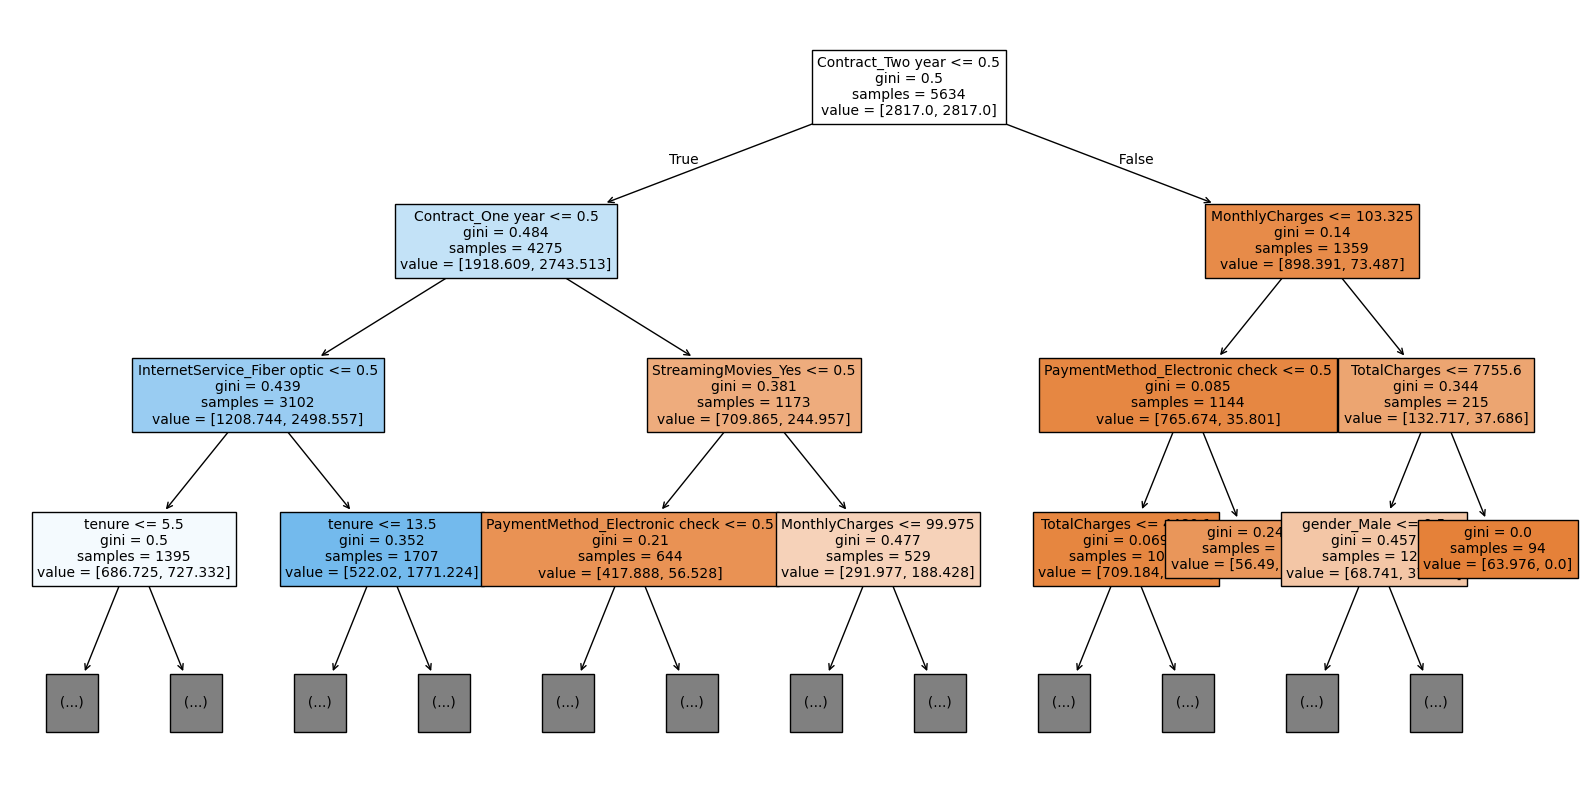

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import recall_score, precision_score, f1_score, confusion_matrix, classification_report

# ==========================================
# 1. LOAD DATA
# ==========================================
file_path = glob.glob(r"C:\Users\Vandana\Downloads\WA_Fn*.csv")[0]
df = pd.read_csv(file_path)

# ==========================================
# 2. CLEAN DATA
# ==========================================
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df = df.drop(columns=['customerID'])
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# ==========================================
# 3. FEATURE ENGINEERING & ENCODING
# ==========================================
service_cols = ['PhoneService','MultipleLines','OnlineSecurity','OnlineBackup',
                'DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
df['TotalServices'] = (df[service_cols] == 'Yes').sum(axis=1)

# Create df_encoded
df_encoded = pd.get_dummies(df, drop_first=True)
print("Encoded Shape:", df_encoded.shape)

# ==========================================
# 4. TRAIN-TEST SPLIT
# ==========================================
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ==========================================
# 5. TRAIN DECISION TREE
# ==========================================
tree = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=50,
    class_weight='balanced',
    random_state=42
)
tree.fit(X_train, y_train)

# ==========================================
# 6. EVALUATE DECISION TREE
# ==========================================
y_pred = tree.predict(X_test)
print("\n--- DECISION TREE RESULTS ---")
print("Recall:", recall_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# ==========================================
# 7. COMPARISON BASELINES
# ==========================================
print("\n--- BASELINE COMPARISONS ---")

# Dummy
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
print("Dummy Baseline Recall:", recall_score(y_test, dummy.predict(X_test)))

# Logistic Regression
lr = LogisticRegression(class_weight='balanced', max_iter=1000)
lr.fit(X_train, y_train)
print("Logistic Regression Recall:", recall_score(y_test, lr.predict(X_test)))

# Random Forest
rf = RandomForestClassifier(class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)
print("Random Forest Recall:", recall_score(y_test, rf.predict(X_test)))

# ==========================================
# 8. FEATURE IMPORTANCE
# ==========================================
print("\n--- TOP 5 FEATURES ---")
importances = tree.feature_importances_
top5 = sorted(zip(X.columns, importances), key=lambda x: -x[1])[:5]
for feat, imp in top5:
    print(f"{feat}: {imp:.4f}")

# ==========================================
# 9. VISUALIZE TREE (Top 3 Levels)
# ==========================================
from sklearn.tree import plot_tree
plt.figure(figsize=(20, 10))
plot_tree(tree, feature_names=X.columns, filled=True, max_depth=3, fontsize=10)
plt.show()